# Churn model

Trains the churn model on payment events. Webhook failures are retried with the shared `retry_policy`, so a flaky
endpoint doesn't drop events.

In [1]:
import pandas as pd
from payments.retry_policy import RetryPolicy

retry_policy = RetryPolicy(max_tries=5, backoff=0.5)

In [2]:
def load_events(path, policy=retry_policy):
    """Reads payment events, retrying flaky reads."""
    return policy.call(pd.read_parquet, path)

In [3]:
events = load_events("s3://acme-data/events/2026-09.parquet")
print(f"loaded {len(events)} events with retry_policy={retry_policy}")

loaded 182340 events with retry_policy=RetryPolicy(max_tries=5, backoff=0.5)


## Model

A gradient-boosted classifier; `ChurnModel` wraps it so the API can load it.

In [4]:
class ChurnModel:
    def __init__(self, depth=6):
        self.depth = depth

    def fit(self, events):
        return self

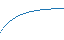

In [5]:
events.groupby("week").churned.mean().plot(title="Churn by week")